# Benchmark de la parte 4: búsqueda por similitud de imágenes
## IVF vs. HNSW · distancia euclidiana vs. coseno

**Pregunta:** ¿qué índice y qué métrica convienen para buscar las k imágenes más parecidas, según el
tamaño de la colección?

Este notebook usa Tiny ImageNet y el mismo pipeline del motor que responde a `SIMILAR_TO('imagen.jpg', k)`:
descriptores SIFT, el vocabulario visual de 256 palabras de `data/modelos/fotos`, histogramas y TF-IDF.
Sobre esos vectores construye los índices vectoriales del motor (`engine.vectorial`: IVF y HNSW sobre
FAISS) con métrica euclidiana y coseno. Mide el tiempo de construcción, el tiempo de consulta, el
Recall@10 contra la búsqueda exacta del motor y la memoria, con k = 10 sobre 1 000, 10 000 y 100 000
imágenes. Las conclusiones se calculan con los datos de esta corrida.

| Sección | Contenido |
| :-- | :-- |
| 1. Preparación | Entorno, dataset verificado, vectores BoVW + TF-IDF y pruebas del motor |
| 2. Diseño experimental | Índices, parámetros, consultas, métricas y unidades |
| 3. Ejecución | Construcción, consultas y barrido de `PROBES` / `EF_SEARCH` por tamaño |
| 4. Resultados | Tablas, gráficas de tiempo, memoria y recall, y galería de aciertos y errores |
| 5. Conclusiones | Análisis calculado y tabla de recomendaciones |

**Reproducción:** ejecutar de arriba abajo desde la raíz o desde `benchmarks/`, con las dependencias de
[README](README.md). Antes hay que descargar el dataset con `python scripts/descargar_tiny_imagenet.py`,
que lo verifica con SHA-256. La primera corrida extrae SIFT de las 110 000 imágenes (unos minutos) y
guarda los histogramas en `data/generated/`; las siguientes los reutilizan si el manifiesto y el
vocabulario no cambiaron.

In [1]:
import csv
import hashlib
import json
import math
import os
import platform
import statistics
import subprocess
import sys
import tempfile
import threading
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter_ns

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "bd2-mpl"))
import cv2
import faiss
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
if ROOT.name == "benchmarks":
    ROOT = ROOT.parent
assert (ROOT / "backend" / "engine").is_dir(), "Ejecutar desde la raíz o benchmarks/"
sys.path.insert(0, str(ROOT / "backend"))

from engine.multimedia.extract_features import ExtractFeatures
from engine.multimedia.histograma import ModeloTfIdf
from engine.multimedia.local_features import SiftExtractor
from engine.multimedia.quantization import load_vocabulary
from engine.vectorial import hnsw as hnsw_module
from engine.vectorial.almacen import AlmacenVectores
from engine.vectorial.exacta import knn_exacto
from engine.vectorial.hnsw import IndiceHNSW
from engine.vectorial.ivf import IndiceIVF
from engine.vectorial.metricas import COSINE, EUCLIDEAN

# Parámetros. Para una comprobación corta: SIZES = (1_000,) y restaurar antes de publicar.
SIZES = (1_000, 10_000, 100_000)
SEED = 2026
TOP_K = 10
PROBES = (1, 2, 4, 8, 16, 32, 64)        # barrido IVF; se agrega PROBES = LISTS (recorre todas las listas)
EF_SEARCH = (10, 20, 40, 80, 160, 320)   # barrido HNSW
HNSW_M, HNSW_EF_CONSTRUCTION = 16, 64     # valores por defecto de CREATE INDEX ... USING HNSW
MEDIA = ROOT / "data" / "multimedia"
DATASET = MEDIA / "tiny-imagenet-200"
VOCABULARY = ROOT / "data" / "modelos" / "fotos" / "vocabulary.json"
CACHE = ROOT / "data" / "generated" / "tiny_imagenet_sift_histogramas.npz"
OUT = ROOT / "benchmarks" / "multimedia_results"
OUT.mkdir(parents=True, exist_ok=True)

METRICS = (EUCLIDEAN, COSINE)
CONFIGS = tuple((kind, metric) for kind in ("ivf", "hnsw") for metric in METRICS)
KIND_LABELS = {"ivf": "IVF", "hnsw": "HNSW", "exacta": "Exacta (SEQ)"}
METRIC_LABELS = {EUCLIDEAN: "euclidiana", COSINE: "coseno"}
COLORS = {"ivf": "#0284c7", "hnsw": "#16a34a", "exacta": "#64748b"}
STYLES = {EUCLIDEAN: "-", COSINE: "--"}
MiB = 2 ** 20

def label(kind, metric):
    return f"{KIND_LABELS[kind]} · {METRIC_LABELS[metric]}"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})

def table(headers, rows):
    """Tabla en texto plano con columnas alineadas."""
    rows = [[str(x) for x in row] for row in rows]
    widths = [max([len(str(h))] + [len(row[i]) for row in rows]) for i, h in enumerate(headers)]
    for row in [[str(h) for h in headers]] + rows:
        print("  ".join(x.ljust(w) for x, w in zip(row, widths)).rstrip())
    print()

def elapsed(action):
    started = perf_counter_ns()
    result = action()
    return result, (perf_counter_ns() - started) / 1_000_000

def p95(values):
    ordered = sorted(values)
    return ordered[math.ceil(len(ordered) * .95) - 1]

def write_csv(path, rows):
    with path.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)

def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

engine_files = sorted((ROOT / "backend" / "engine" / "vectorial").glob("*.py")) + \
               sorted((ROOT / "backend" / "engine" / "multimedia").glob("*.py"))
environment = dict(started_at=datetime.now(timezone.utc).isoformat(), python=sys.version, executable=sys.executable,
                   platform=platform.platform(), cpu_count=os.cpu_count(), seed=SEED, sizes=SIZES, top_k=TOP_K,
                   probes_sweep=PROBES, ef_search_sweep=EF_SEARCH, hnsw_m=HNSW_M, hnsw_ef_construction=HNSW_EF_CONSTRUCTION,
                   hnsw_ef_search_default=hnsw_module.EF_SEARCH, numpy=np.__version__, faiss=faiss.__version__,
                   faiss_omp_threads=faiss.omp_get_max_threads(), opencv=cv2.__version__,
                   source_commit=subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip(),
                   engine_sha256={str(p.relative_to(ROOT)): sha256(p) for p in engine_files},
                   p95_method="nearest_rank", cache="Caché caliente del SO; una consulta de calentamiento por técnica")
table(["Configuración", "Valor"], [("Python", platform.python_version()), ("FAISS", f"{faiss.__version__} · {faiss.omp_get_max_threads()} hilos OpenMP"),
      ("OpenCV", cv2.__version__), ("Tamaños", " · ".join(f"{n:,}" for n in SIZES)), ("k", TOP_K), ("Semilla", SEED),
      ("HNSW", f"M = {HNSW_M}, efConstruction = {HNSW_EF_CONSTRUCTION}, efSearch = {hnsw_module.EF_SEARCH}"),
      ("IVF", "LISTS = round(√n), PROBES = round(√LISTS)")])

Configuración  Valor
Python         3.12.13
FAISS          1.15.1 · 16 hilos OpenMP
OpenCV         5.0.0
Tamaños        1,000 · 10,000 · 100,000
k              10
Semilla        2026
HNSW           M = 16, efConstruction = 64, efSearch = 40
IVF            LISTS = round(√n), PROBES = round(√LISTS)



## 1. Dataset, vectores y pruebas

La especificación ([§2.4.4](../documents/proyectobd2.md)) pide colecciones de 1 000, 10 000 y 100 000
elementos y medir Recall@10. Se usa **Tiny ImageNet**: 110 000 imágenes JPEG de 64 × 64 píxeles de
200 clases (500 de entrenamiento y 50 de validación por clase). `scripts/descargar_tiny_imagenet.py` lo
descarga, verifica el zip con SHA-256 y escribe `manifest.csv`. Aquí se comprueba el hash de ese manifiesto.

**Vectores.** Cada imagen pasa por el mismo pipeline que `POST /api/tables/{tabla}/features`:

1. `SiftExtractor()`: SIFT en escala de grises, hasta 500 puntos (en 64 × 64 salen unos 37 en promedio).
2. Cuantización contra el vocabulario de 256 palabras de `data/modelos/fotos` (K-Means entrenado con
   Caltech-101, no con este dataset): histograma de 256 componentes.
3. `ModeloTfIdf` ajustado **sobre cada colección** (1 000, 10 000 o 100 000), como lo hace el motor
   por tabla. Las consultas se transforman con el modelo de su colección.

Las imágenes en las que SIFT no encuentra ningún punto dan un vector nulo, para el que el coseno no
está definido. Se excluyen y se informa cuántas son.

**Colecciones y consultas.** Las 200 consultas son una imagen de validación por clase, elegida al
azar con la semilla. Ninguna consulta está en la colección, igual que una foto nueva subida a
`SIMILAR_TO`. Las colecciones salen de una permutación con semilla del resto de imágenes y están
anidadas: la de 1 000 está contenida en la de 10 000, y esta en la de 100 000.

**Caché de histogramas.** Extraer SIFT de 110 000 imágenes toma unos minutos. Los histogramas se guardan
en `data/generated/` junto con el hash del manifiesto, el `vocabulary_id` y el `descriptor_id`.
Solo se reutilizan si los tres coinciden. Si no coinciden, el notebook se detiene en lugar de sobrescribir.

In [2]:
verified = json.loads((DATASET / ".verificado.json").read_text(encoding="utf-8")) if (DATASET / ".verificado.json").exists() else None
assert verified, "Falta Tiny ImageNet: ejecutar python scripts/descargar_tiny_imagenet.py"
manifest_sha = sha256(DATASET / "manifest.csv")
assert manifest_sha == verified["manifest_sha256"], "manifest.csv no coincide con el verificado al descargar"
with (DATASET / "manifest.csv").open(newline="", encoding="utf-8") as stream:
    manifest = list(csv.DictReader(stream))
assert len(manifest) == 110_000 and all((MEDIA / row["ruta"]).is_file() for row in manifest[::997])

vocabulary = load_vocabulary(VOCABULARY)
key = dict(manifest_sha256=manifest_sha, vocabulary_id=vocabulary.vocabulary_id, descriptor_id=SiftExtractor().descriptor_id)
if CACHE.exists():
    with np.load(CACHE) as stored:
        assert json.loads(str(stored["clave"])) == key, f"{CACHE.name} se generó con otro manifiesto o vocabulario; bórralo para regenerarlo"
        histograms = stored["histogramas"]
        extraction = json.loads(str(stored["extraccion"]))
    print(f"Histogramas reutilizados de {CACHE.relative_to(ROOT)}")
else:
    cv2.setNumThreads(1)          # el paralelismo es por imagen; OpenCV y NumPy liberan el GIL
    local = threading.local()

    def histogram(row):
        if not hasattr(local, "extraction"):
            local.extraction = ExtractFeatures(SiftExtractor(), vocabulary)   # un detector SIFT por hilo
        return local.extraction.histograma(MEDIA / row["ruta"])

    print(f"Extrayendo SIFT de {len(manifest):,} imágenes con {os.cpu_count()} hilos...", flush=True)
    with ThreadPoolExecutor(os.cpu_count()) as pool:
        histograms, extraction_ms = elapsed(lambda: np.array(list(pool.map(histogram, manifest, chunksize=64))))
    assert histograms.shape == (len(manifest), vocabulary.size) and histograms.max() < 2 ** 16
    histograms = histograms.astype(np.uint16)
    extraction = dict(ms=extraction_ms, hilos=os.cpu_count())
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    temporary = CACHE.with_name(CACHE.name + ".tmp")
    with temporary.open("wb") as stream:
        np.savez_compressed(stream, histogramas=histograms, clave=json.dumps(key), extraccion=json.dumps(extraction))
    temporary.replace(CACHE)

splits = np.array([row["split"] for row in manifest])
wnids = np.array([row["wnid"] for row in manifest])
names = {row["wnid"]: row["clase"] for row in manifest}
classes = sorted(names)
keypoints = histograms.sum(axis=1)
usable = keypoints > 0
rng = np.random.default_rng(SEED)
query_ids = np.array([rng.choice(np.flatnonzero((splits == "val") & (wnids == wnid) & usable)) for wnid in classes])
candidates = np.setdiff1d(np.flatnonzero(usable), query_ids)
order = rng.permutation(candidates)
assert len(order) >= SIZES[-1], "no hay suficientes imágenes con descriptores"
collections = {n: order[:n] for n in SIZES}
for small, big in zip(SIZES, SIZES[1:]):
    assert set(collections[small]) <= set(collections[big])

environment.update(manifest_sha256=manifest_sha, vocabulary_id=vocabulary.vocabulary_id, descriptor_id=key["descriptor_id"],
                   histogram_cache=str(CACHE.relative_to(ROOT)), histogram_cache_sha256=sha256(CACHE), extraction=extraction,
                   excluded_without_descriptors=int((~usable).sum()), query_ids=query_ids.tolist())
table(["Imágenes", "Sin descriptores SIFT (excluidas)", "Puntos SIFT por imagen (media)", "Consultas", "Extracción"],
      [(f"{len(manifest):,}", f"{(~usable).sum():,} ({(~usable).mean():.2%})", f"{keypoints[usable].mean():.1f}",
        f"{len(query_ids)} (1 por clase, validación)", f"{extraction['ms'] / 1000:.0f} s con {extraction['hilos']} hilos")])
table(["Colección", "Clases presentes", "Imágenes por clase (mín–máx)", "De entrenamiento", "Contiene a la anterior"],
      [(f"{n:,}", len(set(wnids[ids])), "{}–{}".format(*(lambda c: (min(c), max(c)))(np.unique(wnids[ids], return_counts=True)[1])),
        f"{(splits[ids] == 'train').mean():.1%}", "—" if n == SIZES[0] else "Sí") for n, ids in collections.items()])

tests = []
for module in ("engine.vectorial.test_vectorial", "engine.vectorial.test_integral",
               "engine.multimedia.test_extract_features", "engine.parser.test_similitud_sql"):
    _, ms = elapsed(lambda: subprocess.run([sys.executable, "-B", "-m", module], cwd=ROOT / "backend",
                                           check=True, capture_output=True, text=True))
    tests.append((module, "OK", f"{ms / 1000:.1f}"))
table(["Prueba", "Resultado", "Duración (s)"], tests)

Histogramas reutilizados de data/generated/tiny_imagenet_sift_histogramas.npz


Imágenes  Sin descriptores SIFT (excluidas)  Puntos SIFT por imagen (media)  Consultas                      Extracción
110,000   127 (0.12%)                        36.6                            200 (1 por clase, validación)  150 s con 16 hilos

Colección  Clases presentes  Imágenes por clase (mín–máx)  De entrenamiento  Contiene a la anterior
1,000      199               1–12                          92.0%             —
10,000     200               34–68                         91.0%             Sí
100,000    200               478–524                       91.1%             Sí



Prueba                                   Resultado  Duración (s)
engine.vectorial.test_vectorial          OK         2.2
engine.vectorial.test_integral           OK         2.7
engine.multimedia.test_extract_features  OK         1.0
engine.parser.test_similitud_sql         OK         2.3



## 2. Diseño experimental

| Técnica | Estructura (FAISS) | Parámetros | Equivale en SQL a |
| :-- | :-- | :-- | :-- |
| IVF | `IndexIVFFlat`: K-Means en `LISTS` celdas; cada vector va a la lista de su centroide | `LISTS = round(√n)`, `PROBES = round(√LISTS)` listas visitadas | `CREATE INDEX ... USING IVF WITH (METRIC=...)` |
| HNSW | `IndexHNSWFlat`: grafo de varios niveles con `M` vecinos por nodo | `M = 16`, `efConstruction = 64`, `efSearch = 40` | `CREATE INDEX ... USING HNSW WITH (METRIC=...)` |
| Exacta | `knn_exacto` del motor: recorre todos los vectores por lotes con un heap de tamaño k | — | `SIMILAR_TO(...) USING SEQ` |

- **Métricas.** Con la euclidiana, FAISS usa `METRIC_L2`. Con coseno, el motor normaliza los vectores
  y usa producto interno; IVF además entrena K-Means esférico. Cada índice se compara con la búsqueda
  exacta de **su misma métrica**.
- **Construcción.** Se mide `construir()` del motor sobre un `AlmacenVectores` ya cargado. Incluye
  leer los vectores del archivo mapeado y, en IVF, entrenar los centroides. Extraer SIFT y ajustar
  TF-IDF queda fuera, porque es común a todas las técnicas y se informa en la sección 1.
- **Consulta.** Se hacen 200 consultas por configuración, después de una pasada de calentamiento sin
  cronómetro con las mismas 200. En corridas de prueba, las primeras consultas después de construir
  salieron hasta 30 veces más lentas y luego se estabilizaron. La causa probable son los hilos OpenMP
  que FAISS usó al construir, aunque no se comprobó. Como esa demora no es parte de la consulta, se
  mide el estado estable. Se mide
  `buscar(q, 10)` del motor, que incluye la búsqueda en FAISS y el recálculo de las distancias de
  los 10 candidatos. Las consultas son de un vector a la vez, como en `SIMILAR_TO`.
- **Exacta contra índices: algoritmo e implementación.** `knn_exacto` está escrito con NumPy y un heap
  en Python, mientras que IVF y HNSW corren en C++ con SIMD (FAISS). Por eso la aceleración frente a
  la exacta mezcla dos efectos: el algoritmo, que visita menos vectores, y la implementación. Por
  ejemplo, IVF con `PROBES = LISTS` recorre todos los vectores igual que la exacta y aun así es más
  rápido. Esa diferencia se debe solo a la implementación.
- **Recall@10.** Es la fracción de los 10 resultados que también está entre los 10 más cercanos de la
  búsqueda exacta. Si hay un empate en la décima distancia, cuenta como acierto, porque cualquiera de
  los vectores empatados es un top-10 válido.
- **Precisión por clase@10.** Es la fracción de los 10 resultados que pertenece a la misma clase
  que la consulta. No es un requisito del enunciado, pero distingue dos cosas: si el índice recupera
  los vecinos correctos (recall) y si esos vecinos se parecen semánticamente (BoVW). Al azar valdría 1/200.
- **Memoria.** Es el tamaño del índice FAISS serializado (`serialize_index`), que es lo que el motor
  guarda en el `.vidx` y lo que ocupa en RAM. IVF y HNSW guardan una copia de los vectores, así que se
  informa también el tamaño de los vectores (n × 256 × 4 bytes).
- **Barrido.** Para cada tamaño y métrica se repiten las 200 consultas con varios valores de `PROBES`
  (IVF) y `EF_SEARCH` (HNSW), los mismos que se pueden pasar en `SIMILAR_TO`. Así se obtiene la curva
  recall contra tiempo. Con `PROBES = LISTS`, IVF recorre todas las listas y debe dar Recall@10 = 1.
- **Verificación fuera del cronómetro.** Cada respuesta debe traer como máximo 10 identificadores distintos y vivos
  (IVF con pocas `PROBES` puede visitar listas con menos de 10 vectores y devolver menos; el recall lo cuenta como fallo),
  con las distancias ordenadas y recalculadas con `engine.vectorial.metricas`. Para 20 consultas por
  tamaño, la búsqueda exacta del motor se compara con un `np.argsort` completo de NumPy. Un fallo detiene la corrida.
- **Entorno.** Todo corre en un solo proceso y con la caché caliente. La construcción usa los hilos
  OpenMP de FAISS. Una consulta individual corre en un solo hilo.

In [3]:
construction, samples, sweep, verified_exact = [], [], [], {}
gallery = {}

def check(found, store):
    distances = [d for d, _ in found]
    ids = [i for _, i in found]
    # IVF con pocas PROBES puede visitar listas con menos de k vectores: devuelve menos y el recall lo castiga
    assert 0 < len(found) <= TOP_K and len(set(ids)) == len(ids) and distances == sorted(distances)
    assert all(store.vivo(i) for i in ids)

def recall(found, exact):
    limit = exact[-1][0] + 1e-5          # distancia del 10.º exacto: un empate también es un top-10 válido
    return sum(d <= limit for d, _ in found) / len(exact)

def class_precision(found, query, members):
    return sum(wnids[members[i]] == wnids[query] for _, i in found) / TOP_K

def run_size(work, n):
    members = collections[n]
    model = ModeloTfIdf.ajustar(histograms[members])
    data = np.array([model.transformar(h) for h in histograms[members]])
    queries = np.array([model.transformar(h) for h in histograms[query_ids]])
    store = AlmacenVectores(str(Path(work) / f"imagenes_{n}"), vocabulary.size)
    store.agregar_lote(data, [(i, 0) for i in range(n)])
    alive = store.ids_vivos()
    assert len(alive) == n and np.array_equal(store.matriz()[alive], data)

    print(f"N={n:,}: búsqueda exacta", flush=True)
    exact = {}
    for metric in METRICS:
        for query in queries[:20]:
            knn_exacto(query, store.matriz(), TOP_K, metric, alive)
        for position, query in enumerate(queries):
            found, ms = elapsed(lambda: knn_exacto(query, store.matriz(), TOP_K, metric, alive))
            check(found, store)
            assert len(found) == TOP_K
            exact[metric, position] = found
            samples.append(dict(n=n, tecnica="exacta", metrica=metric, consulta=int(query_ids[position]), tiempo_ms=ms,
                                devueltos=len(found), recall_10=1.0,
                                precision_clase_10=class_precision(found, query_ids[position], members)))
        for position in range(0, len(queries), len(queries) // 20):       # fuera del cronómetro
            if metric == EUCLIDEAN:
                reference = np.linalg.norm(data - queries[position], axis=1)
            else:
                norms = np.linalg.norm(data, axis=1) * np.linalg.norm(queries[position])
                reference = 1 - (data @ queries[position]) / norms
            tenth = np.sort(reference)[TOP_K - 1]
            assert abs(exact[metric, position][-1][0] - tenth) < 1e-4 and all(reference[i] <= tenth + 1e-4 for _, i in exact[metric, position])
        verified_exact[n] = verified_exact.get(n, 0) + len(range(0, len(queries), len(queries) // 20))

    for kind, metric in CONFIGS:
        print(f"N={n:,}: {label(kind, metric)}", flush=True)
        index = IndiceIVF(store, metric) if kind == "ivf" else IndiceHNSW(store, metric, HNSW_M, HNSW_EF_CONSTRUCTION)
        _, build_ms = elapsed(index.construir)
        index_bytes = int(faiss.serialize_index(index.indice).nbytes)
        for query in queries:          # pasada sin cronómetro: tras construir, las primeras consultas salen más lentas (probablemente hilos OpenMP de FAISS)
            index.buscar(query, TOP_K)
        for position, query in enumerate(queries):
            found, ms = elapsed(lambda: index.buscar(query, TOP_K))
            check(found, store)
            samples.append(dict(n=n, tecnica=kind, metrica=metric, consulta=int(query_ids[position]), tiempo_ms=ms,
                                devueltos=len(found), recall_10=recall(found, exact[metric, position]),
                                precision_clase_10=class_precision(found, query_ids[position], members)))
            if n == SIZES[-1]:
                gallery[kind, metric, position] = [int(members[i]) for _, i in found]
        if kind == "ivf":
            name, values, default = "PROBES", sorted({p for p in PROBES if p < index.lists} | {index.lists}), index.probes_por_defecto()
            search = lambda query, value: index.buscar(query, TOP_K, probes=value)
        else:
            name, values, default = "EF_SEARCH", EF_SEARCH, hnsw_module.EF_SEARCH
            search = lambda query, value: index.buscar(query, TOP_K, ef_search=value)
        for value in values:
            search(queries[0], value)
            times, recalls, returned = [], [], []
            for position, query in enumerate(queries):
                found, ms = elapsed(lambda: search(query, value))
                check(found, store)
                times.append(ms)
                recalls.append(recall(found, exact[metric, position]))
                returned.append(len(found))
            sweep.append(dict(n=n, tecnica=kind, metrica=metric, parametro=name, valor=value, por_defecto=value == default,
                              promedio_ms=statistics.mean(times), p95_ms=p95(times), recall_10=statistics.mean(recalls),
                              devueltos=statistics.mean(returned)))
        if kind == "ivf":
            assert sweep[-1]["recall_10"] == 1.0, f"IVF con PROBES = LISTS debe ser exacto ({label(kind, metric)}, N={n:,})"
        construction.append(dict(n=n, tecnica=kind, metrica=metric, construccion_ms=build_ms, indice_bytes=index_bytes,
                                 vectores_bytes=data.nbytes, lists=getattr(index, "lists", ""),
                                 probes=index.probes_por_defecto() if kind == "ivf" else "",
                                 m=HNSW_M if kind == "hnsw" else "", ef_construction=HNSW_EF_CONSTRUCTION if kind == "hnsw" else "",
                                 ef_search=hnsw_module.EF_SEARCH if kind == "hnsw" else ""))
    store.cerrar()

## 3. Ejecución

Para cada tamaño se ajusta TF-IDF, se cargan los vectores y se ejecuta la búsqueda exacta, que es la
referencia. Después, para cada combinación de índice y métrica, se construye el índice, se miden las
200 consultas con los parámetros por defecto y se hace el barrido. Un fallo detiene la corrida y
conserva el error en el notebook.

In [4]:
with tempfile.TemporaryDirectory(prefix="bd2-vector-") as work:
    # Calentamiento: la primera construcción paga la inicialización de FAISS y OpenMP; no se mide
    warm = AlmacenVectores(str(Path(work) / "calentamiento"), vocabulary.size)
    warm.agregar_lote(np.random.default_rng(SEED).random((500, vocabulary.size), dtype=np.float32), [(i, 0) for i in range(500)])
    for metric in METRICS:
        IndiceIVF(warm, metric).construir()
        IndiceHNSW(warm, metric).construir()
    warm.destruir()
    for n in SIZES:
        run_size(work, n)

environment["finished_at"] = datetime.now(timezone.utc).isoformat()
environment["verified_exact_queries"] = verified_exact
table(["Imágenes", "Consultas por técnica", "Configuraciones", "Puntos del barrido", "Exactas verificadas con NumPy"],
      [(f"{n:,}", len(query_ids), len(CONFIGS) + len(METRICS), sum(1 for s in sweep if s["n"] == n), verified_exact[n]) for n in SIZES])

N=1,000: búsqueda exacta


N=1,000: IVF · euclidiana


N=1,000: IVF · coseno


N=1,000: HNSW · euclidiana


N=1,000: HNSW · coseno


N=10,000: búsqueda exacta


... (6 outputs left out)

N=100,000: IVF · coseno


N=100,000: HNSW · euclidiana


N=100,000: HNSW · coseno


Imágenes  Consultas por técnica  Configuraciones  Puntos del barrido  Exactas verificadas con NumPy
1,000     200                    6                24                  40
10,000    200                    6                28                  40
100,000   200                    6                28                  40



## 4. Resultados

Los tiempos de consulta están en milisegundos por consulta; la construcción, en segundos; la memoria,
en MiB. El P95 usa rango más cercano: la posición `ceil(0.95 × n)` en los tiempos ordenados.

In [5]:
summary = []
for n in SIZES:
    for kind, metric in [("exacta", m) for m in METRICS] + list(CONFIGS):
        rows = [s for s in samples if s["n"] == n and s["tecnica"] == kind and s["metrica"] == metric]
        times = [r["tiempo_ms"] for r in rows]
        built = next((c for c in construction if c["n"] == n and c["tecnica"] == kind and c["metrica"] == metric), None)
        summary.append(dict(n=n, tecnica=kind, metrica=metric, consultas=len(rows), promedio_ms=statistics.mean(times),
                            mediana_ms=statistics.median(times), p95_ms=p95(times),
                            recall_10=statistics.mean(r["recall_10"] for r in rows),
                            precision_clase_10=statistics.mean(r["precision_clase_10"] for r in rows),
                            construccion_ms=built["construccion_ms"] if built else 0.0,
                            indice_bytes=built["indice_bytes"] if built else 0))
write_csv(OUT / "consultas.csv", summary)
write_csv(OUT / "muestras.csv", samples)
write_csv(OUT / "construccion.csv", construction)
write_csv(OUT / "barrido.csv", sweep)
(OUT / "entorno.json").write_text(json.dumps(environment, indent=2, default=str), encoding="utf-8")

def get(n, kind, metric, field):
    return next(r[field] for r in summary if r["n"] == n and r["tecnica"] == kind and r["metrica"] == metric)

print("Construcción, consulta, recall y memoria (parámetros por defecto)")
table(["Imágenes", "Técnica", "Construcción (s)", "Consulta promedio (ms)", "P95 (ms)", "Recall@10", "Precisión por clase@10", "Índice (MiB)", "Vectores (MiB)"],
      [(f"{r['n']:,}", label(r["tecnica"], r["metrica"]), "—" if r["tecnica"] == "exacta" else f"{r['construccion_ms'] / 1000:.3f}",
        f"{r['promedio_ms']:.3f}", f"{r['p95_ms']:.3f}", f"{r['recall_10']:.3f}", f"{r['precision_clase_10']:.3f}",
        "—" if r["tecnica"] == "exacta" else f"{r['indice_bytes'] / MiB:.2f}", f"{r['n'] * vocabulary.size * 4 / MiB:.2f}")
       for r in summary])

Construcción, consulta, recall y memoria (parámetros por defecto)
Imágenes  Técnica                    Construcción (s)  Consulta promedio (ms)  P95 (ms)  Recall@10  Precisión por clase@10  Índice (MiB)  Vectores (MiB)
1,000     Exacta (SEQ) · euclidiana  —                 0.477                   0.680     1.000      0.009                   —             0.98
1,000     Exacta (SEQ) · coseno      —                 0.507                   0.820     1.000      0.013                   —             0.98
1,000     IVF · euclidiana           0.005             0.170                   0.264     0.983      0.008                   1.02          0.98
1,000     IVF · coseno               0.005             0.184                   0.271     0.717      0.009                   1.02          0.98
1,000     HNSW · euclidiana          0.125             0.728                   1.648     0.936      0.008                   1.12          0.98
1,000     HNSW · coseno              0.444             1.156      

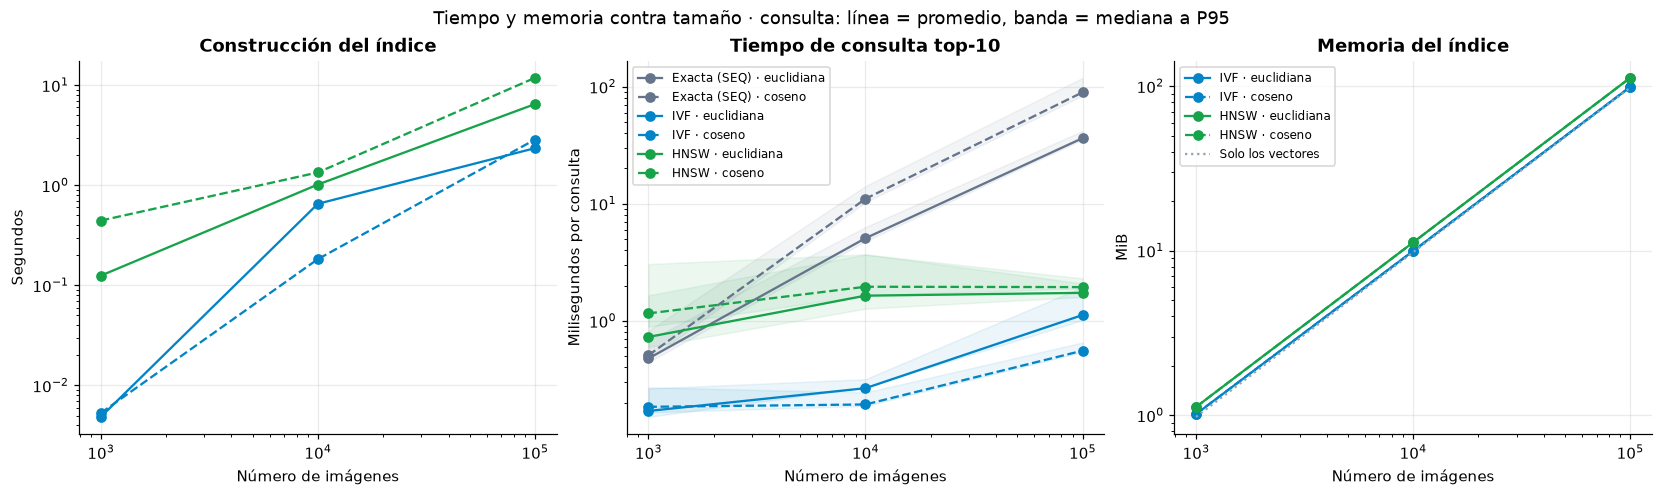

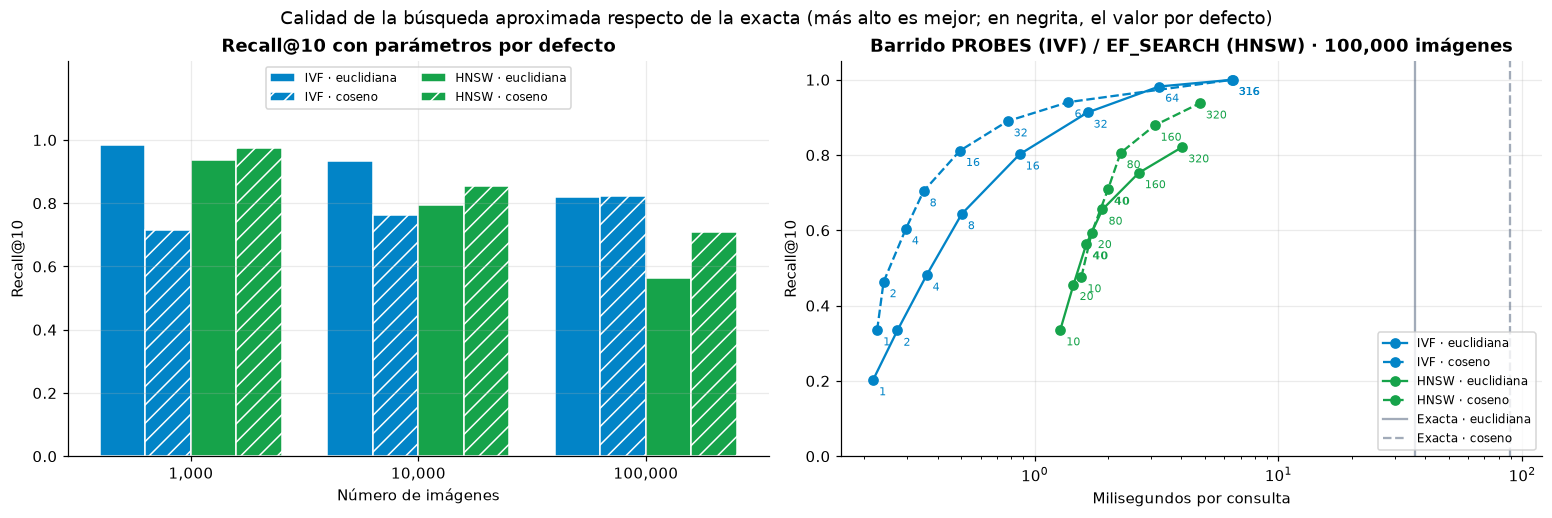

Barrido con 100,000 imágenes
Técnica            Parámetro  Valor         Consulta promedio (ms)  P95 (ms)  Recall@10
IVF · euclidiana   PROBES     1             0.217                   0.250     0.203
IVF · euclidiana   PROBES     2             0.274                   0.350     0.334
IVF · euclidiana   PROBES     4             0.360                   0.453     0.480
IVF · euclidiana   PROBES     8             0.503                   0.603     0.643
IVF · euclidiana   PROBES     16            0.868                   1.030     0.802
IVF · euclidiana   PROBES     32            1.649                   1.881     0.913
IVF · euclidiana   PROBES     64            3.240                   4.126     0.982
IVF · euclidiana   PROBES     316           6.508                   7.149     1.000
IVF · coseno       PROBES     1             0.226                   0.242     0.335
IVF · coseno       PROBES     2             0.240                   0.260     0.463
IVF · coseno       PROBES     4            

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True)
for kind, metric in CONFIGS:
    style = dict(color=COLORS[kind], linestyle=STYLES[metric], marker="o", label=label(kind, metric))
    axes[0].plot(SIZES, [get(n, kind, metric, "construccion_ms") / 1000 for n in SIZES], **style)
    axes[2].plot(SIZES, [get(n, kind, metric, "indice_bytes") / MiB for n in SIZES], **style)
for kind, metric in [("exacta", m) for m in METRICS] + list(CONFIGS):
    style = dict(color=COLORS[kind], linestyle=STYLES[metric], marker="o", label=label(kind, metric))
    axes[1].plot(SIZES, [get(n, kind, metric, "promedio_ms") for n in SIZES], **style)
    axes[1].fill_between(SIZES, [get(n, kind, metric, "mediana_ms") for n in SIZES],
                         [get(n, kind, metric, "p95_ms") for n in SIZES], color=COLORS[kind], alpha=.08)
axes[2].plot(SIZES, [n * vocabulary.size * 4 / MiB for n in SIZES], color="#94a3b8", linestyle=":", label="Solo los vectores")
for ax, title, ylabel in zip(axes, ("Construcción del índice", "Tiempo de consulta top-10", "Memoria del índice"),
                             ("Segundos", "Milisegundos por consulta", "MiB")):
    ax.set(xscale="log", yscale="log", xlabel="Número de imágenes", ylabel=ylabel, title=title)
    ax.grid(True, alpha=.25)
axes[1].legend(fontsize=8)
axes[2].legend(fontsize=8)
fig.suptitle("Tiempo y memoria contra tamaño · consulta: línea = promedio, banda = mediana a P95")
fig.savefig(OUT / "tiempos_memoria.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), constrained_layout=True)
width = .2
for offset, (kind, metric) in enumerate(CONFIGS):
    xs = [i + (offset - 1.5) * width for i in range(len(SIZES))]
    axes[0].bar(xs, [get(n, kind, metric, "recall_10") for n in SIZES], width, color=COLORS[kind],
                hatch="" if metric == EUCLIDEAN else "//", edgecolor="white", label=label(kind, metric))
axes[0].set_xticks(range(len(SIZES)), [f"{n:,}" for n in SIZES])
axes[0].set(ylim=(0, 1.25), yticks=np.linspace(0, 1, 6), xlabel="Número de imágenes", ylabel="Recall@10", title="Recall@10 con parámetros por defecto")
axes[0].legend(fontsize=8, loc="upper center", ncol=2)
big = SIZES[-1]
for kind, metric in CONFIGS:
    points = [s for s in sweep if s["n"] == big and s["tecnica"] == kind and s["metrica"] == metric]
    axes[1].plot([p["promedio_ms"] for p in points], [p["recall_10"] for p in points], color=COLORS[kind],
                 linestyle=STYLES[metric], marker="o", label=label(kind, metric))
    for p in points:
        axes[1].annotate(str(p["valor"]), (p["promedio_ms"], p["recall_10"]), textcoords="offset points", xytext=(4, -10),
                         fontsize=7, color=COLORS[kind], fontweight="bold" if p["por_defecto"] else "normal")
for metric in METRICS:
    axes[1].axvline(get(big, "exacta", metric, "promedio_ms"), color=COLORS["exacta"], linestyle=STYLES[metric], alpha=.6,
                    label=f"Exacta · {METRIC_LABELS[metric]}")
axes[1].set(xscale="log", ylim=(0, 1.05), xlabel="Milisegundos por consulta", ylabel="Recall@10",
            title=f"Barrido PROBES (IVF) / EF_SEARCH (HNSW) · {big:,} imágenes")
axes[1].legend(fontsize=8, loc="lower right")
for ax in axes:
    ax.grid(True, alpha=.25)
fig.suptitle("Calidad de la búsqueda aproximada respecto de la exacta (más alto es mejor; en negrita, el valor por defecto)")
fig.savefig(OUT / "recall.png", dpi=160)
plt.show()

print(f"Barrido con {big:,} imágenes")
table(["Técnica", "Parámetro", "Valor", "Consulta promedio (ms)", "P95 (ms)", "Recall@10"],
      [(label(s["tecnica"], s["metrica"]), s["parametro"], f"{s['valor']}{' (defecto)' if s['por_defecto'] else ''}",
        f"{s['promedio_ms']:.3f}", f"{s['p95_ms']:.3f}", f"{s['recall_10']:.3f}") for s in sweep if s["n"] == big])

### Galería de aciertos y errores

Son consultas reales sobre las 100 000 imágenes con **HNSW · coseno** y sus parámetros por defecto. Se
muestran las tres consultas con más resultados de la misma clase y las tres con menos. El borde
verde marca la misma clase que la consulta y el rojo, otra clase. Un `≠` indica que ese resultado no
está en el top-10 exacto, es decir, que es un error del índice y no del descriptor.

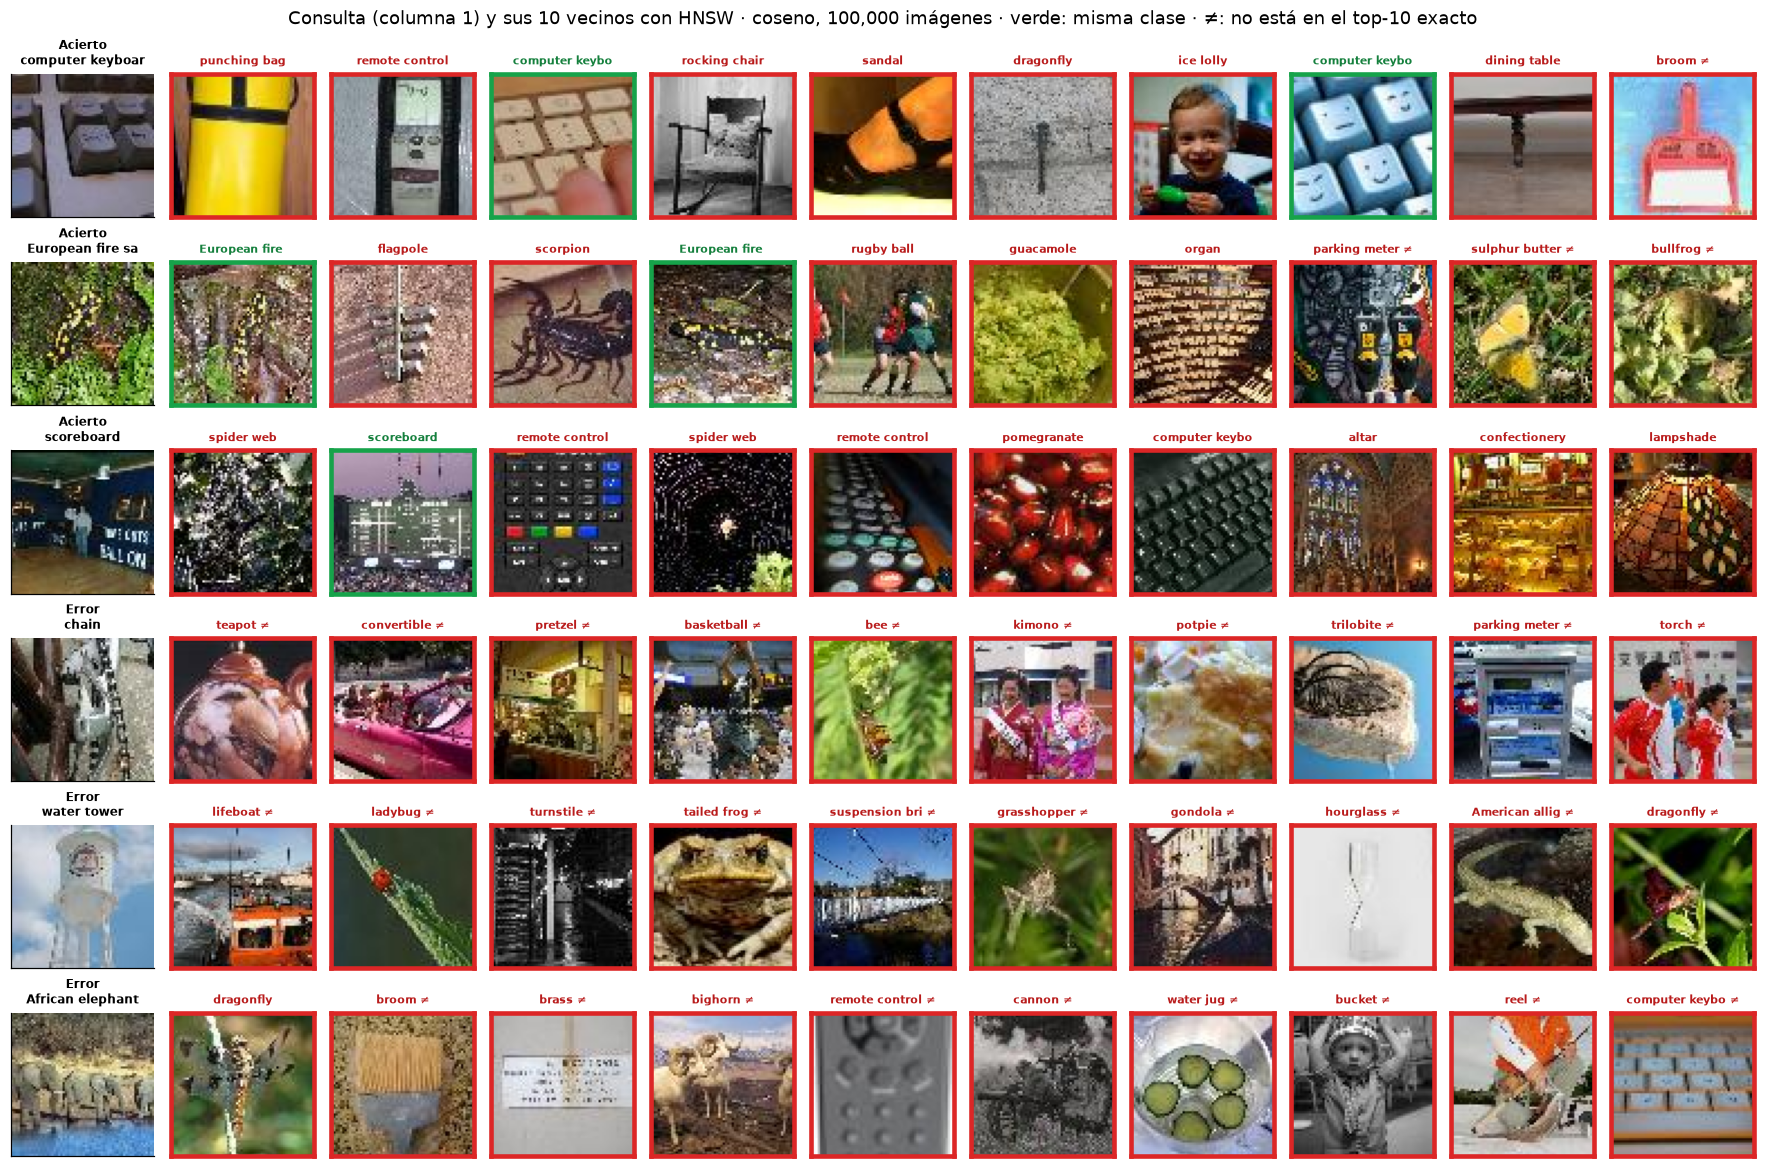

In [7]:
shown_kind, shown_metric = "hnsw", COSINE
big = SIZES[-1]
exact_members = {}
scores = []
for position, query in enumerate(query_ids):
    found = gallery[shown_kind, shown_metric, position]
    same = sum(wnids[i] == wnids[query] for i in found)
    hit = next(s["recall_10"] for s in samples if s["n"] == big and s["tecnica"] == shown_kind
               and s["metrica"] == shown_metric and s["consulta"] == int(query))
    scores.append((same, hit, position))
scores.sort()
chosen = [("Acierto", p) for _, _, p in scores[::-1][:3]] + [("Error", p) for _, _, p in scores[:3]]

# top-10 exacto de las consultas mostradas, para marcar errores del índice (fuera del cronómetro)
model = ModeloTfIdf.ajustar(histograms[collections[big]])
data = np.array([model.transformar(h) for h in histograms[collections[big]]])
data_norm = data / np.linalg.norm(data, axis=1, keepdims=True)
for _, position in chosen:
    query = model.transformar(histograms[query_ids[position]])
    distances = 1 - data_norm @ (query / np.linalg.norm(query))
    tenth = np.sort(distances)[TOP_K - 1]
    exact_members[position] = {int(collections[big][i]) for i in np.flatnonzero(distances <= tenth + 1e-5)}

def image(index):
    return cv2.cvtColor(cv2.imread(str(MEDIA / manifest[index]["ruta"])), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(len(chosen), TOP_K + 1, figsize=(16, 1.75 * len(chosen)), constrained_layout=True)
for row, (kind_of_row, position) in enumerate(chosen):
    query = int(query_ids[position])
    found = gallery[shown_kind, shown_metric, position]
    axes[row, 0].imshow(image(query))
    axes[row, 0].set_title(f"{kind_of_row}\n{names[wnids[query]][:16]}", fontsize=8, fontweight="bold")
    for column, member in enumerate(found, start=1):
        ax = axes[row, column]
        ax.imshow(image(member))
        same = wnids[member] == wnids[query]
        mark = "" if member in exact_members[position] else " ≠"
        ax.set_title(f"{names[wnids[member]][:14]}{mark}", fontsize=7, color="#15803d" if same else "#b91c1c")
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("#16a34a" if same else "#dc2626")
            spine.set_linewidth(3)
    for ax in axes[row]:
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle(f"Consulta (columna 1) y sus 10 vecinos con {label(shown_kind, shown_metric)}, {big:,} imágenes · verde: misma clase · ≠: no está en el top-10 exacto")
fig.savefig(OUT / "galeria.png", dpi=130)
plt.show()

## 5. Conclusiones

El análisis siguiente se calcula con las cifras de esta corrida. Describe este dataset, este
vocabulario, esta máquina y la caché caliente. No permite generalizar a otros descriptores, a índices
en frío ni a consultas concurrentes.

### Ventajas y desventajas de cada índice

| Índice | Ventajas | Desventajas | Cuándo usarlo |
| :-- | :-- | :-- | :-- |
| Exacta (SEQ) | Recall 1, no necesita construcción ni memoria extra, admite cualquier métrica | Su tiempo crece de forma lineal con la colección | Colecciones pequeñas, filtros que dejan pocos candidatos o verificación de otros índices |
| IVF | Construcción rápida (K-Means + asignación); `PROBES` regula el balance entre recall y tiempo; el borrado es real (`remove_ids`) | Hay que entrenarlo con la tabla ya cargada; si los datos cambian mucho, los centroides envejecen; el recall cae si los vecinos quedan en listas no visitadas | Colecciones grandes que se reconstruyen seguido o en las que importa la memoria |
| HNSW | Consultas rápidas cuyo costo crece poco con la colección; `EF_SEARCH` se ajusta por consulta; las inserciones son incrementales | Construcción más lenta; el grafo agrega memoria (2·`M` enlaces por nodo en la capa 0 y `M` en las superiores); los borrados solo se filtran al consultar; con `M` y `EF_SEARCH` fijos, su recall cae al crecer la colección, sobre todo con vectores de alta dimensión (ver el barrido) | Colecciones grandes y estables donde manda la latencia, ajustando `EF_SEARCH` al tamaño |

Los usos combinan las mediciones anteriores con propiedades conocidas de cada estructura. No se afirma
un umbral universal de tamaño. Euclidiana y coseno se comparan con el mismo vector TF-IDF. Para
histogramas, el coseno suele ser la opción natural porque compara qué palabras visuales pesan más, sin
importar la norma del vector. La tabla anterior indica si esta corrida lo confirma. Que HNSW suela tener
el mejor balance entre recall y tiempo es un resultado general sobre embeddings densos. Con histogramas
BoVW de 256 dimensiones, el barrido de esta corrida es la evidencia que vale.

## Archivos de esta corrida

- [Resumen por técnica y tamaño](multimedia_results/consultas.csv) y [cada consulta](multimedia_results/muestras.csv)
  con su tiempo, Recall@10 y precisión por clase.
- [Construcción y memoria](multimedia_results/construccion.csv), [barrido de PROBES y EF_SEARCH](multimedia_results/barrido.csv)
  y [entorno, parámetros y hashes](multimedia_results/entorno.json).
- Figuras: [tiempo y memoria](multimedia_results/tiempos_memoria.png), [recall y barrido](multimedia_results/recall.png)
  y [galería](multimedia_results/galeria.png).
- [Descarga del dataset](../scripts/descargar_tiny_imagenet.py), [pipeline multimedia](../docs/13-multimedia.md)
  y [enunciado](../documents/proyectobd2.md).

Los histogramas SIFT son regenerables y quedan en `data/generated/`.